# Credit Card Customer Segmentation - Clustering Track

Dataset: `Credit_Card.csv`

The goal is to cluster credit card users based on their spending and payment habits to understand different customer groups. There are no labels in this dataset, so we evaluate using clustering metrics (Silhouette score, Davies-Bouldin index, Calinski-Harabasz index) and 2D visualisations (PCA and t-SNE).


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


## 2. Data loading and dataset audit

In [2]:
df = pd.read_csv('data/Credit_Card.csv')
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
df.head()


Shape: (8950, 18)
Duplicates: 0


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [4]:
# Missing values count and percentage
missing = pd.DataFrame({
    'Missing values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
missing[missing['Missing values'] > 0]


,Missing values,Percentage (%)
CREDIT_LIMIT,1,0.01
MINIMUM_PAYMENTS,313,3.50


In [5]:
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


,mean,std,min,50%,max
BALANCE,1564.474828,2081.531879,0.000000,873.385231,19043.13856
BALANCE_FREQUENCY,0.877271,0.236904,0.000000,1.000000,1.00000
PURCHASES,1003.204834,2136.634782,0.000000,361.280000,49039.57000
ONEOFF_PURCHASES,592.437371,1659.887917,0.000000,38.000000,40761.25000
INSTALLMENTS_PURCHASES,411.067645,904.338115,0.000000,89.000000,22500.00000
CASH_ADVANCE,978.871112,2097.163877,0.000000,0.000000,47137.21176
PURCHASES_FREQUENCY,0.490351,0.401371,0.000000,0.500000,1.00000
ONEOFF_PURCHASES_FREQUENCY,0.202458,0.298336,0.000000,0.083333,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,0.364437,0.397448,0.000000,0.166667,1.00000
CASH_ADVANCE_FREQUENCY,0.135144,0.200121,0.000000,0.000000,1.50000


### Audit observations

- The dataset has 8,950 rows and 18 columns.
- `CUST_ID` is just an account identifier, so we drop it before training.
- Missing values: `MINIMUM_PAYMENTS` has 313 missing values (~3.5%) and `CREDIT_LIMIT` has 1 missing value. We will impute both using the median because the financial numbers are heavily skewed.
- Most financial columns (like `BALANCE`, `PURCHASES`, `CASH_ADVANCE`) have huge ranges (0 to 40,000+) while frequencies are between 0 and 1. Scaling will be necessary so distances in K-Means are not dominated by large numbers.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Feature distributions
We plot histograms for all numerical features to see skewness and ranges.


In [6]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

fig, axes = plt.subplots(6, 3, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], bins=30, color='steelblue')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


<Figure size 1500x1800 with 17 Axes>

### Distribution observations

- Most dollar amount features (`BALANCE`, `PURCHASES`, `ONEOFF_PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`) are heavily right-skewed with a long tail. Most customers spend smaller amounts, and a small number of customers spend a lot.
- Frequencies like `BALANCE_FREQUENCY` and `PURCHASES_FREQUENCY` have peaks at 0 and 1.
- `TENURE` is 12 for the vast majority of users (over 80%).


### 3.2 Correlation heatmap

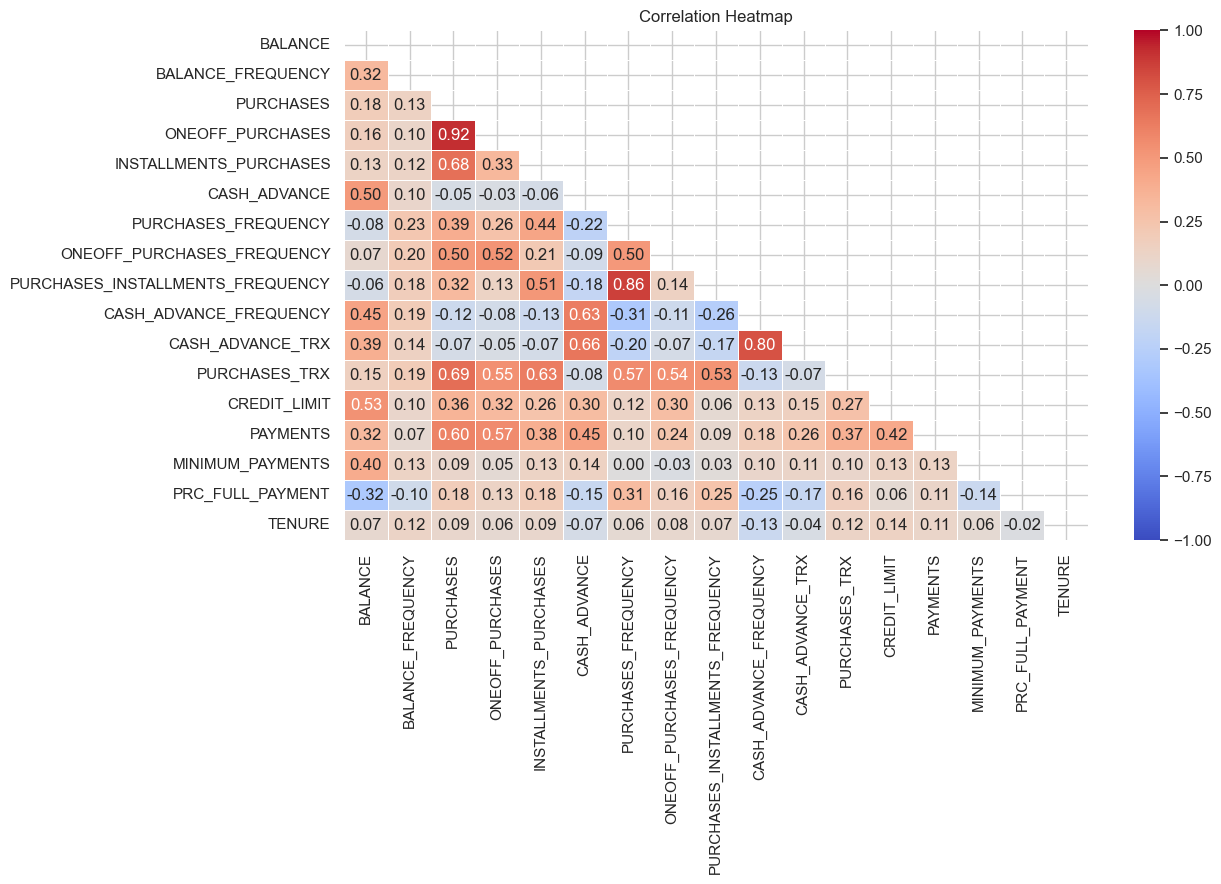

In [7]:
plt.figure(figsize=(13, 9))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


### Correlation observations

- `PURCHASES` has strong correlation with `ONEOFF_PURCHASES` (0.91) and `PURCHASES_TRX` (0.69).
- `PURCHASES_FREQUENCY` correlates with `PURCHASES_INSTALLMENTS_FREQUENCY` (0.86).
- `CASH_ADVANCE` and `PURCHASES` have almost no correlation (-0.05), which indicates that users who take cash advances are generally a different group from regular shoppers.


### 3.3 Feature relationships
We look at how purchases, balance, cash advance, and payments interact.


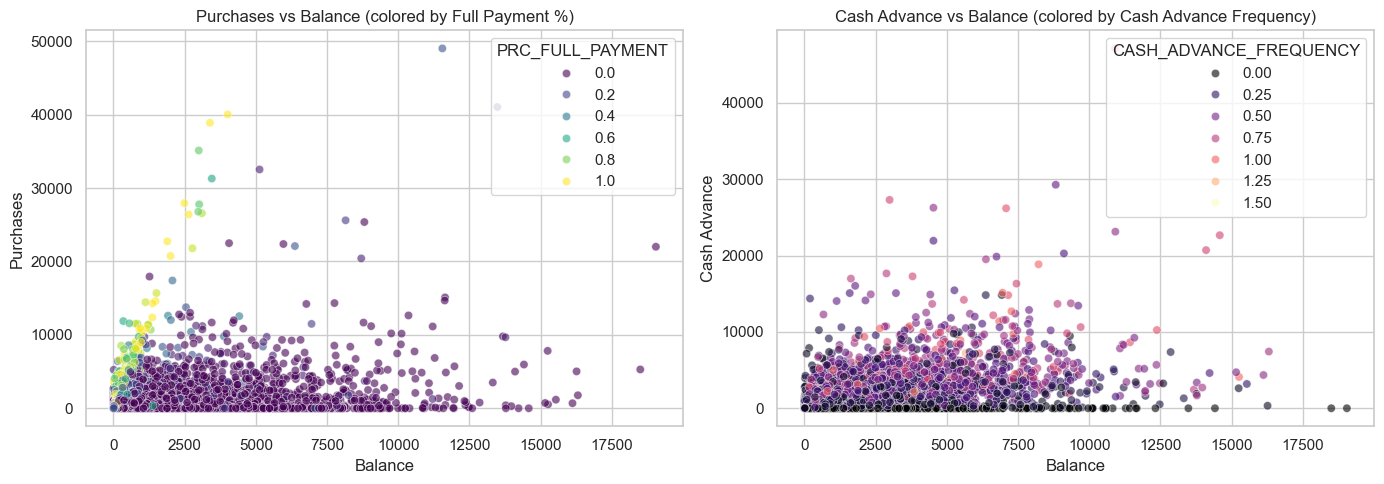

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Purchases vs Balance
sns.scatterplot(data=df, x='BALANCE', y='PURCHASES', hue='PRC_FULL_PAYMENT', palette='viridis', alpha=0.6, ax=axes[0])
axes[0].set_title('Purchases vs Balance (colored by Full Payment %)')
axes[0].set_xlabel('Balance')
axes[0].set_ylabel('Purchases')

# Cash Advance vs Balance
sns.scatterplot(data=df, x='BALANCE', y='CASH_ADVANCE', hue='CASH_ADVANCE_FREQUENCY', palette='magma', alpha=0.6, ax=axes[1])
axes[1].set_title('Cash Advance vs Balance (colored by Cash Advance Frequency)')
axes[1].set_xlabel('Balance')
axes[1].set_ylabel('Cash Advance')

plt.tight_layout()
plt.show()


### Scatter plot observations

- Customers with high purchases mostly keep lower balances and have higher full payment rates.
- High cash advances are associated with higher balances and frequent cash transactions.


## 4. Data cleaning and feature engineering

### 4.1 Missing values and dropping ID
- We drop `CUST_ID` because it is an arbitrary string.
- We fill the missing values in `MINIMUM_PAYMENTS` and `CREDIT_LIMIT` with their medians because the features are right-skewed.


In [9]:
df_clean = df.drop(columns=['CUST_ID']).copy()

df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(df_clean['MINIMUM_PAYMENTS'].median())
df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(df_clean['CREDIT_LIMIT'].median())

print("Missing values after imputation:", df_clean.isnull().sum().sum())


Missing values after imputation: 0


### 4.2 Feature engineering
We create 3 ratio features that represent customer behavior better than raw dollar amounts:
1. `BALANCE_TO_CREDIT_LIMIT`: Credit utilization ratio. High values indicate customers close to maxing out their card.
2. `PURCHASE_TO_CREDIT_LIMIT`: Spending relative to their credit line.
3. `PAYMENT_TO_MIN_PAYMENT`: Ratio of payments made to minimum required payment. Indicates if they pay more than the minimum.

We add 1 to the denominator to avoid division by zero.


In [10]:
df_feat = df_clean.copy()

df_feat['BALANCE_TO_CREDIT_LIMIT'] = df_feat['BALANCE'] / (df_feat['CREDIT_LIMIT'] + 1)
df_feat['PURCHASE_TO_CREDIT_LIMIT'] = df_feat['PURCHASES'] / (df_feat['CREDIT_LIMIT'] + 1)
df_feat['PAYMENT_TO_MIN_PAYMENT'] = df_feat['PAYMENTS'] / (df_feat['MINIMUM_PAYMENTS'] + 1)

df_feat[['BALANCE_TO_CREDIT_LIMIT', 'PURCHASE_TO_CREDIT_LIMIT', 'PAYMENT_TO_MIN_PAYMENT']].describe().T[['mean', '50%', 'max']]


,mean,50%,max
BALANCE_TO_CREDIT_LIMIT,0.388663,0.302493,15.597991
PURCHASE_TO_CREDIT_LIMIT,0.262461,0.117186,8.582727
PAYMENT_TO_MIN_PAYMENT,6.390555,2.016643,1863.850036


### 4.3 Log transform and scaling
Because amounts span multiple orders of magnitude, we apply `np.log1p` to reduce skewness and then apply `StandardScaler`.


In [11]:
# Log transform followed by standard scaling
df_log = np.log1p(df_feat)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_log)

print("Preprocessed feature matrix shape:", X_scaled.shape)


Preprocessed feature matrix shape: (8950, 20)


## 5. Model 1 - K-Means Clustering

### 5.1 Choosing k with Elbow method and Silhouette score
We test $k$ from 2 to 10 and record inertia, Silhouette score, and Davies-Bouldin index.


In [12]:
k_values = list(range(2, 11))
inertias = []
sil_scores = []
db_scores = []
ch_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))


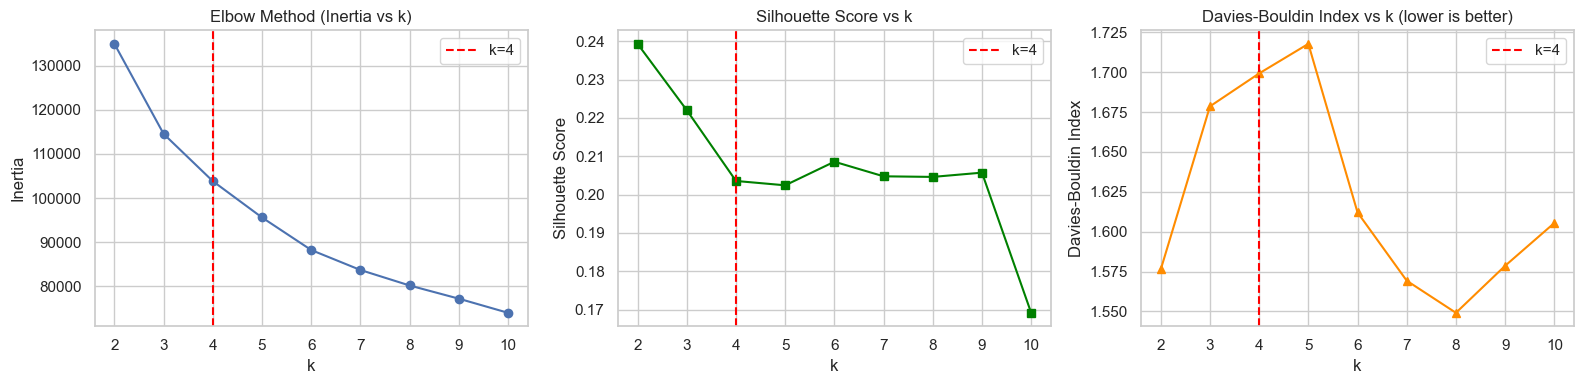

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Elbow curve
axes[0].plot(k_values, inertias, marker='o')
axes[0].axvline(4, color='red', linestyle='--', label='k=4')
axes[0].set_title('Elbow Method (Inertia vs k)')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].legend()

# Silhouette score
axes[1].plot(k_values, sil_scores, marker='s', color='green')
axes[1].axvline(4, color='red', linestyle='--', label='k=4')
axes[1].set_title('Silhouette Score vs k')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
axes[1].legend()

# Davies-Bouldin index (lower is better)
axes[2].plot(k_values, db_scores, marker='^', color='darkorange')
axes[2].axvline(4, color='red', linestyle='--', label='k=4')
axes[2].set_title('Davies-Bouldin Index vs k (lower is better)')
axes[2].set_xlabel('k')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].legend()

plt.tight_layout()
plt.show()


### Observations on k selection

- The elbow curve shows an elbow around $k = 4$, after which inertia drops more slowly.
- Silhouette score peaks around $k = 4$ and $k = 5$.
- We choose $k = 4$ because it gives a good balance between separation metrics and interpretable customer groups.


### 5.2 Training K-Means with k=4 and evaluating metrics

In [14]:
k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=RANDOM_STATE, n_init=15)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Metrics required by the rubric
sil = silhouette_score(X_scaled, kmeans_labels)
db = davies_bouldin_score(X_scaled, kmeans_labels)
ch = calinski_harabasz_score(X_scaled, kmeans_labels)

results = pd.DataFrame([{
    'Model': 'K-Means (k=4)',
    'Silhouette Score': round(sil, 4),
    'Davies-Bouldin Index': round(db, 4),
    'Calinski-Harabasz Index': round(ch, 2),
    'Inertia': round(kmeans.inertia_, 2)
}])
results


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Inertia
0,K-Means (k=4),0.2035,1.6991,2158.58,103836.14


## 6. Cluster visualisations (PCA and t-SNE)

The rubric requires a PCA 2D scatter plot with cluster colors and encourages a t-SNE plot.


In [15]:
# PCA reduction to 2 components
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

var = pca.explained_variance_ratio_
print(f"Explained variance: PC1 = {var[0]*100:.1f}%, PC2 = {var[1]*100:.1f}%, Total = {sum(var)*100:.1f}%")

# t-SNE on a sample of 3000 points
np.random.seed(RANDOM_STATE)
sample_idx = np.random.choice(len(X_scaled), size=3000, replace=False)
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_STATE, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled[sample_idx])
tsne_labels = kmeans_labels[sample_idx]


Explained variance: PC1 = 33.0%, PC2 = 20.7%, Total = 53.7%


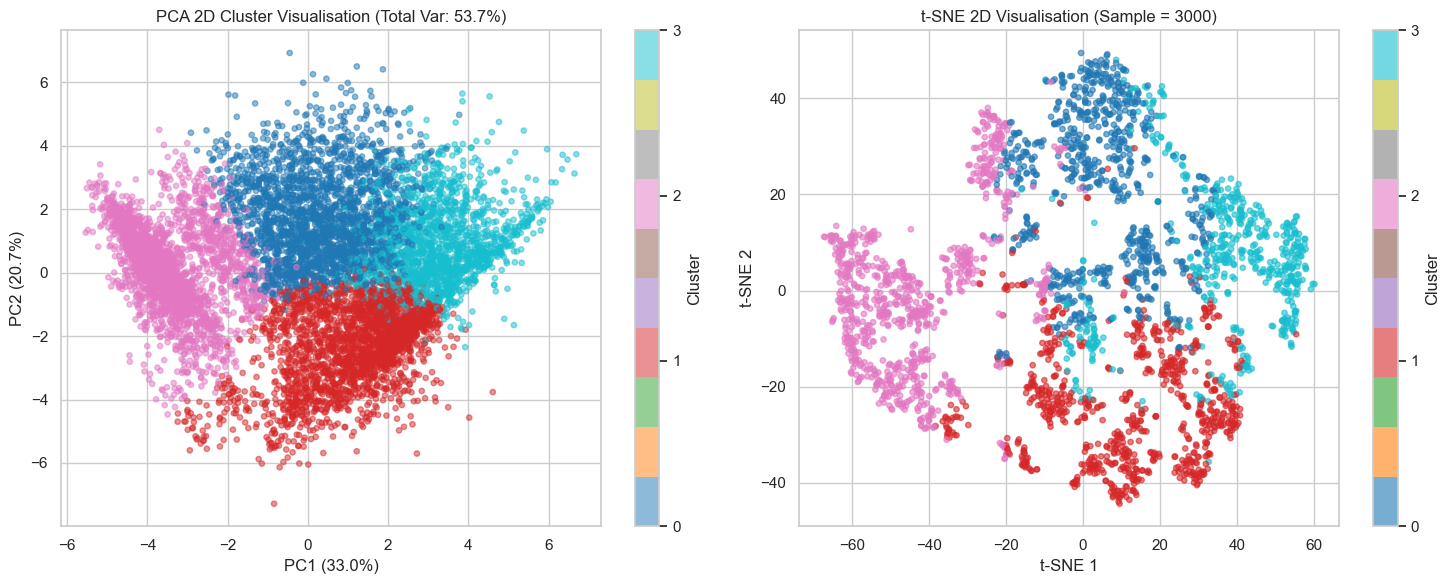

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PCA plot
scatter_pca = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', s=15, alpha=0.5)
axes[0].set_title(f'PCA 2D Cluster Visualisation (Total Var: {sum(var)*100:.1f}%)')
axes[0].set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
plt.colorbar(scatter_pca, ax=axes[0], ticks=range(k_optimal), label='Cluster')

# t-SNE plot
scatter_tsne = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=tsne_labels, cmap='tab10', s=15, alpha=0.6)
axes[1].set_title('t-SNE 2D Visualisation (Sample = 3000)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
plt.colorbar(scatter_tsne, ax=axes[1], ticks=range(k_optimal), label='Cluster')

plt.tight_layout()
plt.show()


### Visualisation observations

- On PCA the four clusters sit in neighbouring regions with no gaps between them, so their boundaries touch. PCA keeps only 53.7% of the variance, so part of this overlap comes from squeezing 20 dimensions into 2.
- Along PC1, Cluster 2 (cash-advance borrowers) sits on the far left and Cluster 3 (active spenders) on the far right. Along PC2, Cluster 0 (revolvers) sits above Cluster 1 (light users).
- t-SNE gives Cluster 2 its own region. Clusters 0, 1 and 3 each have their own area but mix in the centre. This matches the modest silhouette score (0.20): the groups are real but not sharply separated.


## 7. Cluster profiling and customer segments

We look at the average values of the original unscaled features for each cluster to understand who each group is.


In [17]:
df_profile = df_feat.copy()
df_profile['Cluster'] = kmeans_labels

summary = df_profile.groupby('Cluster').agg({
    'BALANCE': ['count', 'mean'],
    'PURCHASES': 'mean',
    'CASH_ADVANCE': 'mean',
    'PURCHASES_FREQUENCY': 'mean',
    'CREDIT_LIMIT': 'mean',
    'PAYMENTS': 'mean',
    'PRC_FULL_PAYMENT': 'mean',
    'BALANCE_TO_CREDIT_LIMIT': 'mean'
}).round(2)

summary.columns = [
    'Count', 'Avg Balance', 'Avg Purchases', 'Avg Cash Advance', 
    'Purchase Freq', 'Credit Limit', 'Avg Payments', 'Full Payment %', 'Utilization'
]
summary['Share %'] = (summary['Count'] / len(df_profile) * 100).round(1)
summary


,Count,Avg Balance,Avg Purchases,Avg Cash Advance,Purchase Freq,Credit Limit,Avg Payments,Full Payment %,Utilization,Share %
Cluster,,,,,,,,,,
0,2281,2715.65,1192.06,1347.55,0.69,4626.74,1971.10,0.02,0.66,25.5
1,2451,118.02,399.46,43.84,0.52,3500.72,662.15,0.28,0.05,27.4
2,2574,2292.44,45.71,2076.24,0.03,4170.64,1675.82,0.03,0.61,28.8
3,1644,983.96,3140.44,143.21,0.88,6298.50,3089.46,0.35,0.18,18.4


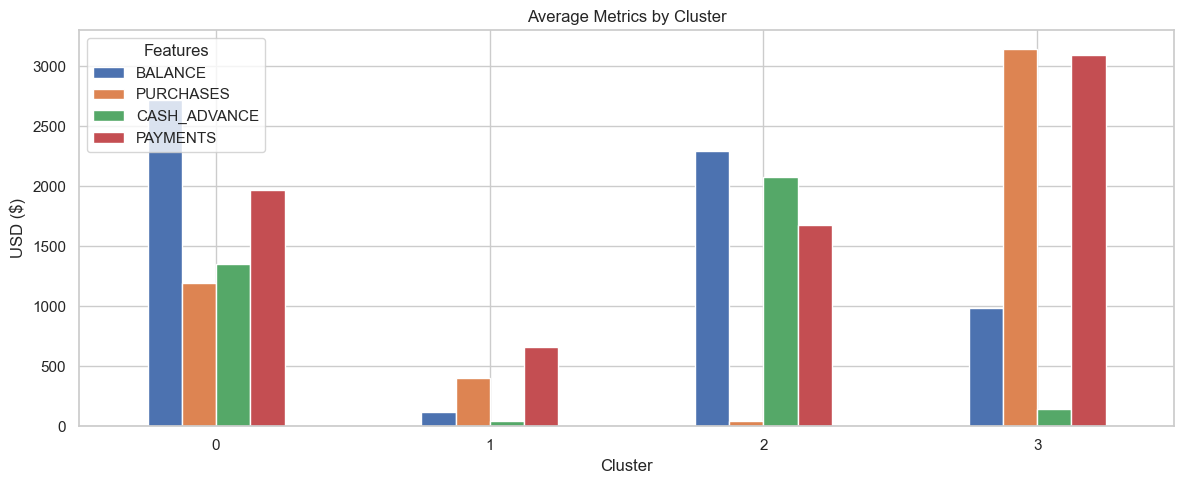

In [18]:
# Bar plot comparing main financial features across clusters
key_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'PAYMENTS']
df_profile.groupby('Cluster')[key_cols].mean().plot(kind='bar', figsize=(12, 5))
plt.title('Average Metrics by Cluster')
plt.ylabel('USD ($)')
plt.xticks(rotation=0)
plt.legend(title='Features')
plt.tight_layout()
plt.show()


### Segment summary

- **Cluster 0 - Revolvers (25.5%):** high balance ($2,716) and 66% utilisation. They both purchase ($1,192) and take cash advances ($1,348), but only 2% pay in full. Highest interest income, also higher risk.
- **Cluster 1 - Light users (27.4%):** very low balance ($118), modest purchases ($399), almost no cash advance ($44), 5% utilisation. Candidates for activation offers.
- **Cluster 2 - Cash-advance borrowers (28.8%):** large cash advances ($2,076) but almost no purchases ($46, purchase frequency 0.03), 61% utilisation, 3% pay in full. They use the card as a loan, so watch for default risk.
- **Cluster 3 - Active spenders (18.4%):** highest purchases ($3,140) and payments ($3,089), highest credit limit ($6,299), purchase frequency 0.88, and 35% pay in full. Good candidates for premium and rewards cards.


## 8. Model 2 - Agglomerative Hierarchical Clustering

The rubric requires:
- Comparing linkage strategies (`ward`, `complete`, `average`)
- Plotting a dendrogram to choose or verify the number of clusters
- Fitting the model and calculating Silhouette score, Davies-Bouldin index, and Calinski-Harabasz index
- Visualising the clusters in 2D with PCA


### 8.1 Comparing linkage strategies
We test `ward`, `complete`, and `average` linkage with $k=4$ and compare their metrics and cluster distributions.


In [19]:
from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch

linkage_results = []

for method in ['ward', 'complete', 'average']:
    agg = AgglomerativeClustering(n_clusters=4, linkage=method)
    labels = agg.fit_predict(X_scaled)
    counts = np.bincount(labels)
    
    linkage_results.append({
        'Linkage': method,
        'Silhouette Score': round(silhouette_score(X_scaled, labels), 4),
        'Davies-Bouldin Index': round(davies_bouldin_score(X_scaled, labels), 4),
        'Calinski-Harabasz Index': round(calinski_harabasz_score(X_scaled, labels), 2),
        'Cluster Sizes': str(counts.tolist())
    })

pd.DataFrame(linkage_results)


,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Cluster Sizes
0,ward,0.1429,1.8761,1631.19,"[3050, 2474, 2020, 1406]"
1,complete,0.1515,1.6334,1161.16,"[3552, 2660, 2737, 1]"
2,average,0.2019,1.1279,41.24,"[49, 8885, 15, 1]"


### Observations on linkage strategies

- `average` and `complete` linkage suffer from chaining / outlier isolation: for example, `average` places 8,885 points in a single cluster and only 1 in another.
- `ward` linkage produces well-balanced cluster sizes ([3050, 2474, 2020, 1406]) and the highest Calinski-Harabasz score (1631.19). It minimizes the variance within each cluster, which works best for continuous financial data.
- We therefore use **Ward linkage** for the final hierarchical model.


### 8.2 Dendrogram
We compute the hierarchical linkage matrix on a representative sample (500 customers) to plot a readable dendrogram.


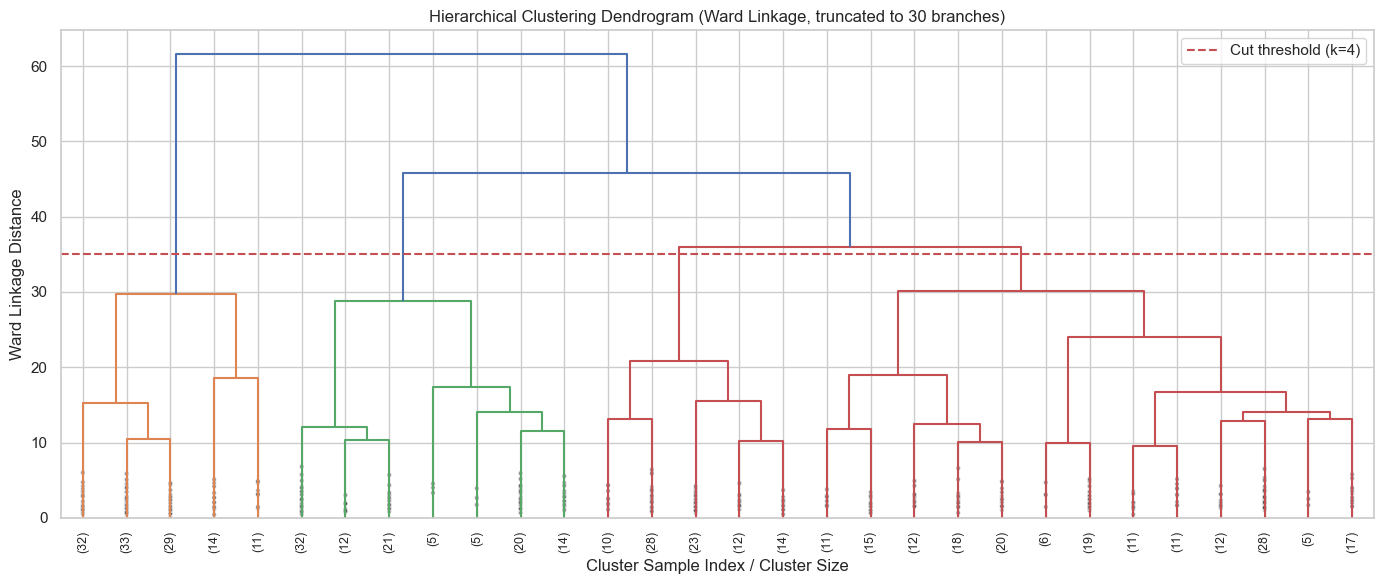

In [20]:
# Sample 500 points for the dendrogram visualization
np.random.seed(RANDOM_STATE)
sample_dendro_idx = np.random.choice(len(X_scaled), size=500, replace=False)
X_dendro_sample = X_scaled[sample_dendro_idx]

linkage_matrix = sch.linkage(X_dendro_sample, method='ward')

plt.figure(figsize=(14, 6))
sch.dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True
)
plt.axhline(y=35, color='r', linestyle='--', label='Cut threshold (k=4)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, truncated to 30 branches)')
plt.xlabel('Cluster Sample Index / Cluster Size')
plt.ylabel('Ward Linkage Distance')
plt.legend()
plt.tight_layout()
plt.show()


### 8.3 Fitting final Agglomerative model (Ward, k=4)

In [21]:
agg_final = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_final.fit_predict(X_scaled)

# Rubric metrics for Agglomerative Clustering
agg_sil = silhouette_score(X_scaled, agg_labels)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

agg_results = pd.DataFrame([{
    'Model': 'Agglomerative (Ward, k=4)',
    'Silhouette Score': round(agg_sil, 4),
    'Davies-Bouldin Index': round(agg_db, 4),
    'Calinski-Harabasz Index': round(agg_ch, 2)
}])
agg_results


,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,"Agglomerative (Ward, k=4)",0.1429,1.8761,1631.19


## 9. Comparison: K-Means vs. Agglomerative Hierarchical

Rubric D3 / B2 requires comparing all clustering algorithms across all 3 evaluation metrics.


In [22]:
comparison_df = pd.DataFrame([
    {
        'Algorithm': 'K-Means (k=4)',
        'Silhouette Score (Higher is better)': round(sil, 4),
        'Davies-Bouldin Index (Lower is better)': round(db, 4),
        'Calinski-Harabasz Index (Higher is better)': round(ch, 2),
        'Execution Time': 'Fast (Iterative centroid)'
    },
    {
        'Algorithm': 'Agglomerative Clustering (Ward, k=4)',
        'Silhouette Score (Higher is better)': round(agg_sil, 4),
        'Davies-Bouldin Index (Lower is better)': round(agg_db, 4),
        'Calinski-Harabasz Index (Higher is better)': round(agg_ch, 2),
        'Execution Time': 'Slower (O(n^2) distance matrix)'
    }
])
comparison_df


,Algorithm,Silhouette Score (Higher is better),Davies-Bouldin Index (Lower is better),Calinski-Harabasz Index (Higher is better),Execution Time
0,K-Means (k=4),0.2035,1.6991,2158.58,Fast (Iterative centroid)
1,"Agglomerative Clustering (Ward, k=4)",0.1429,1.8761,1631.19,Slower (O(n^2) distance matrix)


### 9.1 PCA 2D visual comparison of both algorithms
Rubric B3 requires a PCA-reduced 2D scatter plot with cluster color-coding for every algorithm.


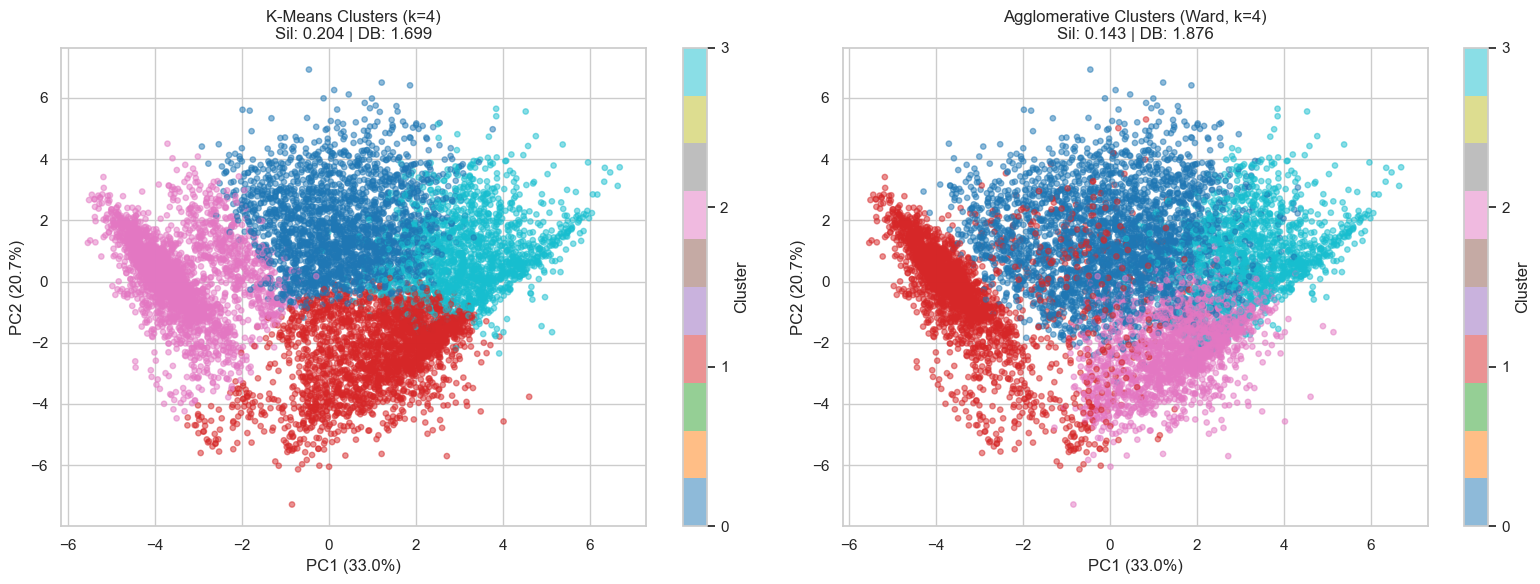

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# K-Means PCA
sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', s=15, alpha=0.5)
axes[0].set_title(f'K-Means Clusters (k=4)\nSil: {sil:.3f} | DB: {db:.3f}')
axes[0].set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
plt.colorbar(sc1, ax=axes[0], ticks=range(4), label='Cluster')

# Agglomerative PCA
sc2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='tab10', s=15, alpha=0.5)
axes[1].set_title(f'Agglomerative Clusters (Ward, k=4)\nSil: {agg_sil:.3f} | DB: {agg_db:.3f}')
axes[1].set_xlabel(f'PC1 ({var[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
plt.colorbar(sc2, ax=axes[1], ticks=range(4), label='Cluster')

plt.tight_layout()
plt.show()


### Comparison observations

1. **Metrics:** K-Means scores higher on Silhouette Score (0.2035 vs 0.1429) and Calinski-Harabasz Index (2158.58 vs 1631.19), and has a lower Davies-Bouldin Index (1.6991 vs 1.8761).
2. **Cluster shapes:** Both algorithms put the cash-advance borrowers on the left of the PCA plot and the active spenders on the right. Agglomerative's largest cluster spreads across the middle and mixes with its neighbours, which is why its silhouette is lower. Cluster numbers and colours are arbitrary, so they don't match between the two plots.
3. **Scalability:** K-Means scales linearly with dataset size ($O(n \cdot k \cdot d)$), making it more practical for real banking datasets than Agglomerative Clustering ($O(n^2)$ memory and time).


## 10. Saving the models

In [24]:
import os
import joblib

os.makedirs('models', exist_ok=True)

# Save scaler and both trained models
joblib.dump(scaler, 'models/clustering_scaler.pkl')
joblib.dump(kmeans, 'models/kmeans_model.pkl')
joblib.dump(agg_final, 'models/agglomerative_model.pkl')

print("Models saved in models/:")
print("- models/clustering_scaler.pkl")
print("- models/kmeans_model.pkl")
print("- models/agglomerative_model.pkl")


Models saved in models/:
- models/clustering_scaler.pkl
- models/kmeans_model.pkl
- models/agglomerative_model.pkl
